# FLIGHT DELAY PREDICTION - MACHINE LEARNING PROJECT

In [1]:
# IMPORTS
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## EDA - Data Understanding & Quality Assessment

In [2]:
# Read csv 
df = pd.read_csv("flightinfo.csv")
# Inspect the first five records.
df.head()

,DAY_OF_WEEK,FL_DATE,OP_UNIQUE_CARRIER,OP_CARRIER_FL_NUM,ORIGIN,DEST,CRS_DEP_TIME,DEP_TIME,DEP_DELAY,DEP_DEL15,CRS_ARR_TIME,CANCELLED,CANCELLATION_CODE,DIVERTED,DISTANCE
0,1,1/6/2025 12:00:00 AM,AA,1,JFK,LAX,659,703.0,4.0,0.0,1020,0.0,NaN,0.0,2475.0
1,1,1/6/2025 12:00:00 AM,AA,10,LAS,JFK,2238,2228.0,-10.0,0.0,630,0.0,NaN,0.0,2248.0
2,1,1/6/2025 12:00:00 AM,AA,1002,MSN,CLT,644,645.0,1.0,0.0,1005,0.0,NaN,0.0,708.0
3,1,1/6/2025 12:00:00 AM,AA,1004,PHL,LAS,1855,1928.0,33.0,1.0,2134,0.0,NaN,0.0,2176.0
4,1,1/6/2025 12:00:00 AM,AA,1005,ORD,PHX,830,845.0,15.0,1.0,1131,0.0,NaN,0.0,1440.0


In [3]:
# DATASET OVERVIEW

In [4]:
# Determine the number of rows and columns.
df.shape

(539747, 15)

In [5]:
# Identify numerical and categorical features.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 539747 entries, 0 to 539746
Data columns (total 15 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   DAY_OF_WEEK        539747 non-null  int64  
 1   FL_DATE            539747 non-null  object 
 2   OP_UNIQUE_CARRIER  539747 non-null  object 
 3   OP_CARRIER_FL_NUM  539747 non-null  int64  
 4   ORIGIN             539747 non-null  object 
 5   DEST               539747 non-null  object 
 6   CRS_DEP_TIME       539747 non-null  int64  
 7   DEP_TIME           523861 non-null  float64
 8   DEP_DELAY          523824 non-null  float64
 9   DEP_DEL15          523824 non-null  float64
 10  CRS_ARR_TIME       539747 non-null  int64  
 11  CANCELLED          539747 non-null  float64
 12  CANCELLATION_CODE  16312 non-null   object 
 13  DIVERTED           539747 non-null  float64
 14  DISTANCE           539747 non-null  float64
dtypes: float64(6), int64(4), object(5)
memory usage: 61

#### CONCLUSION
The dataset contains 539,747 flight records and 15 columns.
Features include flight identifiers, airline and airport information, scheduled departure times, actual departure delays, and cancellation indicators. 
Some numerical columns represent categorical information, while `FL_DATE` requires datetime conversion.

## MISSING VALUES ANALYSIS

In [6]:
# Calculate the number of missing values per column.
missing_values = df.isna().sum()
missing_values

DAY_OF_WEEK               0
FL_DATE                   0
OP_UNIQUE_CARRIER         0
OP_CARRIER_FL_NUM         0
ORIGIN                    0
DEST                      0
CRS_DEP_TIME              0
DEP_TIME              15886
DEP_DELAY             15923
DEP_DEL15             15923
CRS_ARR_TIME              0
CANCELLED                 0
CANCELLATION_CODE    523435
DIVERTED                  0
DISTANCE                  0
dtype: int64

DEP_TIME - 15886 missing values
DEP_DELAY, DEP_DEL15 - 15923 missing values
CANCELLATION_CODE - 523435 missing values

In [7]:
# Calculate the percentage of missing values.
percentage = missing_values/len(df.index)*100
percentage

DAY_OF_WEEK           0.000000
FL_DATE               0.000000
OP_UNIQUE_CARRIER     0.000000
OP_CARRIER_FL_NUM     0.000000
ORIGIN                0.000000
DEST                  0.000000
CRS_DEP_TIME          0.000000
DEP_TIME              2.943231
DEP_DELAY             2.950086
DEP_DEL15             2.950086
CRS_ARR_TIME          0.000000
CANCELLED             0.000000
CANCELLATION_CODE    96.977843
DIVERTED              0.000000
DISTANCE              0.000000
dtype: float64

#### CONCLUSION
CANCELLATION_CODE contains approximately 96.98% missing values, primarily because cancellation reasons are recorded only for cancelled flights.
DEP_TIME, DEP_DELAY, and DEP_DEL15 contain approximately 2.94–2.95% missing values. Their relationship with flight cancellations and diversions requires further investigation before preprocessing.

## MISSING TARGET INVESTIGATION

In [8]:
# Count the total number of cancelled flights.
total_cancelled = df["CANCELLED"].value_counts()
total_cancelled

CANCELLED
0.0    523435
1.0     16312
Name: count, dtype: int64

Total of 16312 

In [9]:
# Count the total number of diverted flights.
cancellation_rate = df["CANCELLED"].value_counts().loc[1.0] / df["CANCELLED"].count()*100
cancellation_rate

np.float64(3.022156677109831)

In [10]:
# Investigate how many flights with missing DEP_DELAY values were cancelled.
filt = df[(df["CANCELLED"]==1)&(df["DEP_DELAY"].isna())]
filt.shape[0]

15923

15923 flights were cancelled

In [11]:
# Investigate whether any non-cancelled flights have missing DEP_DELAY values.
non_cancelled = df[(df["CANCELLED"]==0)&(df["DEP_DELAY"].isna())]
non_cancelled.shape[0]

0

#### CONCLUSION
No non-cancelled flights have missing DEP_DELAY values. Assuming CANCELLED contains only 0 and 1, all 15,923 missing departure delay values are associated with cancelled flights.
Cancelled flights will be excluded from the initial departure delay classification dataset, since their actual departure delay is unavailable.

## TARGET DISTRIBUTION & CLASS IMBALANCE

In [12]:
# Define the eligible flight population for the initial classification experiment.
model_df = df[(df["CANCELLED"]==0) & (df["DEP_DEL15"].notna())].copy()
model_df

,DAY_OF_WEEK,FL_DATE,OP_UNIQUE_CARRIER,OP_CARRIER_FL_NUM,ORIGIN,DEST,CRS_DEP_TIME,DEP_TIME,DEP_DELAY,DEP_DEL15,CRS_ARR_TIME,CANCELLED,CANCELLATION_CODE,DIVERTED,DISTANCE
0,1,1/6/2025 12:00:00 AM,AA,1,JFK,LAX,659,703.0,4.0,0.0,1020,0.0,NaN,0.0,2475.0
1,1,1/6/2025 12:00:00 AM,AA,10,LAS,JFK,2238,2228.0,-10.0,0.0,630,0.0,NaN,0.0,2248.0
2,1,1/6/2025 12:00:00 AM,AA,1002,MSN,CLT,644,645.0,1.0,0.0,1005,0.0,NaN,0.0,708.0
3,1,1/6/2025 12:00:00 AM,AA,1004,PHL,LAS,1855,1928.0,33.0,1.0,2134,0.0,NaN,0.0,2176.0
4,1,1/6/2025 12:00:00 AM,AA,1005,ORD,PHX,830,845.0,15.0,1.0,1131,0.0,NaN,0.0,1440.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
539742,7,1/26/2025 12:00:00 AM,YX,5858,DCA,JFK,1135,1125.0,-10.0,0.0,1255,0.0,NaN,0.0,213.0
539743,7,1/26/2025 12:00:00 AM,YX,5860,MCO,RDU,1110,1104.0,-6.0,0.0,1300,0.0,NaN,0.0,534.0
539744,7,1/26/2025 12:00:00 AM,YX,5861,CMH,LGA,1755,1751.0,-4.0,0.0,1946,0.0,NaN,0.0,479.0
539745,7,1/26/2025 12:00:00 AM,YX,5862,RDU,MCO,1405,1355.0,-10.0,0.0,1604,0.0,NaN,0.0,534.0


#### CONCLUSION
The initial analysis dataset contains 523,435 non-cancelled flights with valid departure delay labels. Cancelled flights were excluded to ensure a clearly defined target population.

In [13]:
# Examine the distribution of DEP_DEL15.

In [14]:
model_df["DEP_DEL15"].value_counts()

DEP_DEL15
0.0    428003
1.0     95432
Name: count, dtype: int64

In [15]:
# Calculate the percentage of flights in each class.
percentage = model_df["DEP_DEL15"].value_counts(normalize=True)*100
percentage

DEP_DEL15
0.0    81.768128
1.0    18.231872
Name: proportion, dtype: float64

#### CONCLUSION

The target distribution is imbalanced: approximately 81.77% of flights are non-delayed, while 18.23% are delayed by at least 15 minutes.

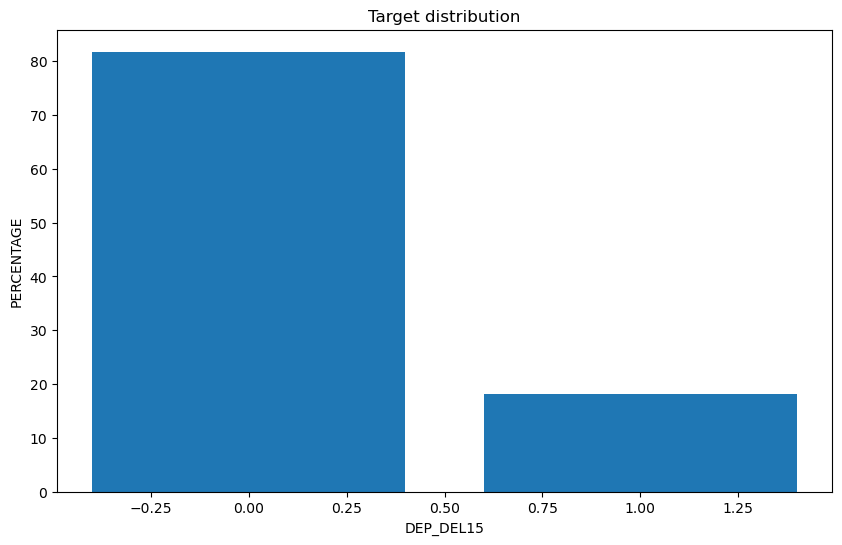

In [16]:
# Visualize the target distribution.

plt.figure(figsize=(10,6))
plt.bar(percentage.index,percentage.values)

plt.xlabel("DEP_DEL15")
plt.ylabel("PERCENTAGE")
plt.title("Target distribution")

plt.show()

#### CONCLUSION

The bar chart shows an imbalanced target distribution, with approximately 81.77% non-delayed flights and 18.23% delayed flights.
The target distribution is imbalanced, with non-delayed flights representing the majority class.
A majority-class baseline would achieve approximately 81.77% accuracy while failing to detect any delayed flights.
No resampling techniques will be applied at this stage. Their necessity will be assessed after evaluating the baseline model.

## FEATURE ANALYSIS & DATA LEAKAGE PPREVENTION

### ORIGIN FEATURE ANALYSIS

In [17]:
# Group flights by ORIGIN.
model_df.groupby("ORIGIN")

In [18]:
# Calculate the total number of flights for each airport.
total_flights = model_df.groupby("ORIGIN").size()
total_flights

ORIGIN
ABE     227
ABI     146
ABQ    1763
ABR      61
ABY      63
       ... 
WRG      59
XNA     897
XWA     177
YAK      55
YUM     142
Length: 329, dtype: int64

In [19]:
# Calculate the percentage of flights with DEP_DEL15 = 1.
delay_rates= model_df.groupby("ORIGIN")["DEP_DEL15"].mean()*100

#### CONCLUSION
Departure delay rates vary across origin airports. Further analysis is needed to identify the highest and lowest rates and assess the reliability of estimates based on small sample sizes.

In [20]:
# Identify airports with the highest and lowest delay rates.
# Lowest 5 delay rates
delay_rates.sort_values().head(5)

ORIGIN
PQI    0.000000
OTH    0.000000
EKO    3.225806
PSG    3.636364
OTZ    4.000000
Name: DEP_DEL15, dtype: float64

In [21]:
# Highest 5 delay rates
delay_rates.sort_values(ascending = False).head(5)

ORIGIN
CKB    77.777778
HGR    57.894737
USA    44.897959
TOL    43.333333
SCE    37.500000
Name: DEP_DEL15, dtype: float64

In [22]:
# Consider whether airports with very few flights provide reliable comparisons.
data = {
         "total_flights":total_flights,
         "delay_rate":delay_rates}
new_df = pd.DataFrame(data)
new_df

,total_flights,delay_rate
ORIGIN,,
ABE,227,13.215859
ABI,146,12.328767
ABQ,1763,12.989223
ABR,61,13.114754
ABY,63,20.634921
...,...,...
WRG,59,15.254237
XNA,897,18.283166
XWA,177,33.333333


In [23]:
new_df.sort_values(by="delay_rate", ascending=False).head(5)

,total_flights,delay_rate
ORIGIN,,
CKB,9,77.777778
HGR,19,57.894737
USA,49,44.897959
TOL,30,43.333333
SCE,16,37.500000


In [24]:
new_df.sort_values(by="delay_rate", ascending=True).head(5)

,total_flights,delay_rate
ORIGIN,,
PQI,31,0.000000
OTH,17,0.000000
EKO,31,3.225806
PSG,55,3.636364
OTZ,25,4.000000


#### CONCLUSION
Departure delay rates vary across origin airports. However, airports with the highest and lowest observed rates have small sample sizes, ranging from 9 to 55 flights.
These extreme rates may be unstable and should be interpreted cautiously.
ORIGIN remains a candidate predictive feature, but its usefulness must be evaluated during model validation.

### CRS_DEP_TIME FEATURE ANALYSIS

In [25]:
# Examine the distribution and validity of CRS_DEP_TIME.

In [26]:
# Check the data type of CRS_DEP_TIME.
model_df["CRS_DEP_TIME"].dtype

dtype('int64')

In [27]:
# Count missing values.
model_df["CRS_DEP_TIME"].isna().sum()

np.int64(0)

In [28]:
#Inspect unique scheduled departure times.
model_df["CRS_DEP_TIME"].unique()

array([ 659, 2238,  644, ..., 2346,  139,  320], shape=(1209,))

In [29]:
# Identify the minimum and maximum values.
model_df["CRS_DEP_TIME"].describe()

count    523435.000000
mean       1315.294711
std         479.690972
min           5.000000
25%         905.000000
50%        1310.000000
75%        1724.000000
max        2359.000000
Name: CRS_DEP_TIME, dtype: float64

In [30]:
# Extract the scheduled departure hour (0–23).
hours = model_df["CRS_DEP_TIME"] // 100
hours 

0          6
1         22
2          6
3         18
4          8
          ..
539742    11
539743    11
539744    17
539745    14
539746    13
Name: CRS_DEP_TIME, Length: 523435, dtype: int64

In [31]:
minutes = model_df["CRS_DEP_TIME"] % 100
minutes

0         59
1         38
2         44
3         55
4         30
          ..
539742    35
539743    10
539744    55
539745     5
539746    55
Name: CRS_DEP_TIME, Length: 523435, dtype: int64

In [32]:
cond = (hours > 23) | (minutes > 59)
cond.sum()

np.int64(0)

In [33]:
df_time = model_df.copy()
df_time["DEPART_HOUR"] = hours
df_time

,DAY_OF_WEEK,FL_DATE,OP_UNIQUE_CARRIER,OP_CARRIER_FL_NUM,ORIGIN,DEST,CRS_DEP_TIME,DEP_TIME,DEP_DELAY,DEP_DEL15,CRS_ARR_TIME,CANCELLED,CANCELLATION_CODE,DIVERTED,DISTANCE,DEPART_HOUR
0,1,1/6/2025 12:00:00 AM,AA,1,JFK,LAX,659,703.0,4.0,0.0,1020,0.0,NaN,0.0,2475.0,6
1,1,1/6/2025 12:00:00 AM,AA,10,LAS,JFK,2238,2228.0,-10.0,0.0,630,0.0,NaN,0.0,2248.0,22
2,1,1/6/2025 12:00:00 AM,AA,1002,MSN,CLT,644,645.0,1.0,0.0,1005,0.0,NaN,0.0,708.0,6
3,1,1/6/2025 12:00:00 AM,AA,1004,PHL,LAS,1855,1928.0,33.0,1.0,2134,0.0,NaN,0.0,2176.0,18
4,1,1/6/2025 12:00:00 AM,AA,1005,ORD,PHX,830,845.0,15.0,1.0,1131,0.0,NaN,0.0,1440.0,8
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
539742,7,1/26/2025 12:00:00 AM,YX,5858,DCA,JFK,1135,1125.0,-10.0,0.0,1255,0.0,NaN,0.0,213.0,11
539743,7,1/26/2025 12:00:00 AM,YX,5860,MCO,RDU,1110,1104.0,-6.0,0.0,1300,0.0,NaN,0.0,534.0,11
539744,7,1/26/2025 12:00:00 AM,YX,5861,CMH,LGA,1755,1751.0,-4.0,0.0,1946,0.0,NaN,0.0,479.0,17
539745,7,1/26/2025 12:00:00 AM,YX,5862,RDU,MCO,1405,1355.0,-10.0,0.0,1604,0.0,NaN,0.0,534.0,14


In [34]:
df_time[["CRS_DEP_TIME","DEPART_HOUR"]].head()

,CRS_DEP_TIME,DEPART_HOUR
0,659,6
1,2238,22
2,644,6
3,1855,18
4,830,8


In [35]:
# Calculate the number of flights for each hour.
total_flights2 = df_time.groupby("DEPART_HOUR").size()
total_flights2

DEPART_HOUR
0       564
1       282
2        93
3        55
4        25
5     13432
6     35288
7     36684
8     37751
9     31417
10    32132
11    34945
12    32072
13    31897
14    31883
15    30865
16    30959
17    33901
18    32518
19    26258
20    22380
21    14705
22     9689
23     3640
dtype: int64

In [36]:
# Calculate the percentage of delayed flights for each hour.
delay_rates2 = df_time.groupby("DEPART_HOUR")["DEP_DEL15"].mean()*100
delay_rates2 

DEPART_HOUR
0     15.248227
1     18.085106
2     23.655914
3     20.000000
4     36.000000
5      8.904110
6      8.073566
7     10.037073
8     11.856640
9     14.460324
10    16.833686
11    18.125626
12    19.618359
13    20.133555
14    21.575761
15    22.151304
16    22.255241
17    22.376921
18    23.162556
19    24.148831
20    25.008937
21    24.365862
22    22.716483
23    16.593407
Name: DEP_DEL15, dtype: float64

In [37]:
data2 = {"total_flights":total_flights2,
        "delay_rate": delay_rates2}
new_df2 = pd.DataFrame(data2)
new_df2

,total_flights,delay_rate
DEPART_HOUR,,
0,564,15.248227
1,282,18.085106
2,93,23.655914
3,55,20.000000
4,25,36.000000
5,13432,8.904110
6,35288,8.073566
7,36684,10.037073
8,37751,11.856640


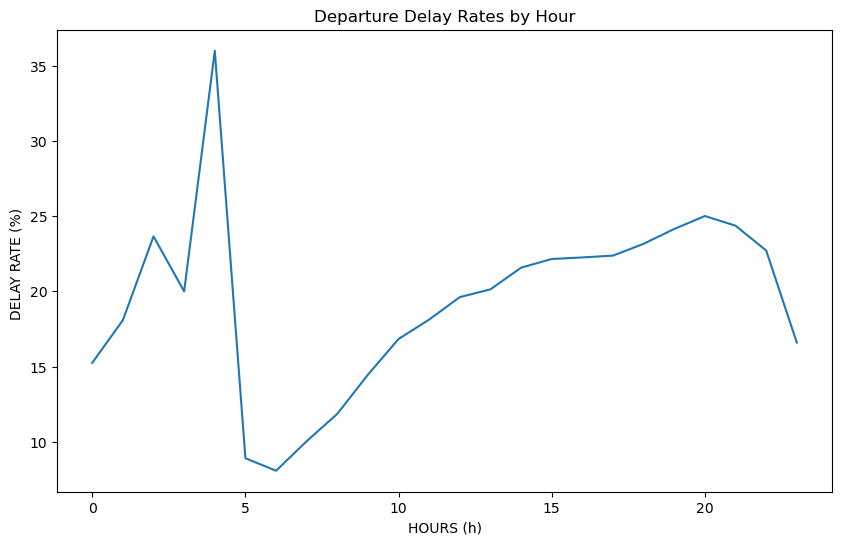

In [38]:
# Visualize departure delay rates by hour.
plt.figure(figsize=(10,6))

plt.plot(delay_rates2 .index,delay_rates2 .values)

plt.xlabel("HOURS (h)")
plt.ylabel("DELAY RATE (%) ")
plt.title("Departure Delay Rates by Hour")

plt.show()


#### CONCLUSION
Departure delay rates generally increase throughout the day, from 8.07% at 06:00 to 25.01% at 20:00. Overnight rates are less reliable due to smaller sample sizes. Scheduled departure hour may be a useful predictive feature.
Its contribution will be tested by comparing models with and without this feature using the same validation strategy.

In [39]:
model_df["DEPART_HOUR"] = df_time["DEPART_HOUR"] 

### DISTANCE FEATURE ANALYSIS

In [40]:
# Check the data type
model_df["DISTANCE"].dtype

dtype('float64')

In [41]:
# Check missing values
model_df["DISTANCE"].isna().sum()

np.int64(0)

In [42]:
# Examine minimum, maximum, mean, and median distances
model_df["DISTANCE"].describe()

count    523435.000000
mean        847.642255
std         602.294238
min          31.000000
25%         404.000000
50%         715.000000
75%        1085.000000
max        5095.000000
Name: DISTANCE, dtype: float64

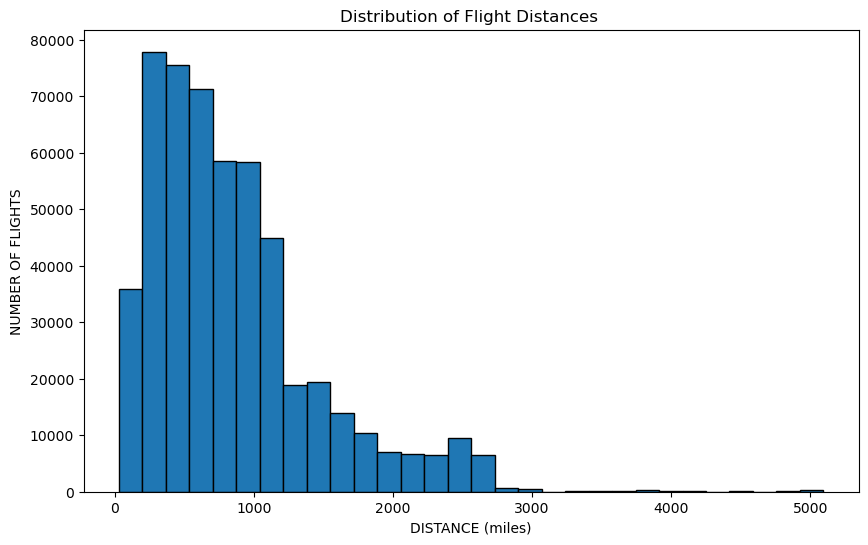

In [43]:
# Visualize the distribution of flight distances.
plt.figure(figsize=(10,6))
plt.hist(model_df["DISTANCE"],bins=30,edgecolor="black")

plt.xlabel("DISTANCE (miles)")
plt.ylabel("NUMBER OF FLIGHTS")
plt.title("Distribution of Flight Distances ")
plt.show()

#### CONCLUSION
Flight distances are right-skewed, with most flights covering shorter distances. Long-distance flights above 3,000 miles are relatively rare and contribute to the long right tail of the distribution.

In [44]:
# Group flights into distance ranges and compare the departure delay rate across groups.
model_df["DIST_CATEG"] = pd.cut(model_df["DISTANCE"], bins=[0,500,1000,2000,5095], labels=["Short","Medium","Long","Very Long"], right=True)

In [45]:
model_df["DIST_CATEG"].value_counts()

DIST_CATEG
Medium       186753
Short        175856
Long         128250
Very Long     32576
Name: count, dtype: int64

Medium-distance flights are the most common, followed by Short and Long flights. Very Long flights are less frequent but still have enough observations for meaningful comparisons.

In [46]:
total_flights3 = model_df.groupby("DIST_CATEG", observed=True).size()
total_flights3

DIST_CATEG
Short        175856
Medium       186753
Long         128250
Very Long     32576
dtype: int64

In [47]:
delay_rate3 = model_df.groupby("DIST_CATEG", observed=True)["DEP_DEL15"].mean()*100
delay_rate3 

DIST_CATEG
Short        17.011077
Medium       18.813085
Long         19.585965
Very Long    16.159136
Name: DEP_DEL15, dtype: float64

In [48]:
data3 = {
    "total_flights": total_flights3,
    "delay_rate3": delay_rate3
}
new_df3 = pd.DataFrame(data3)
new_df3

,total_flights,delay_rate3
DIST_CATEG,,
Short,175856,17.011077
Medium,186753,18.813085
Long,128250,19.585965
Very Long,32576,16.159136


#### CONCLUSION
Departure delay rates increase from Short (17.01%) to Long flights (19.59%), but decrease for Very Long flights (16.16%). The relationship is not strictly increasing, suggesting that flight distance may contain useful predictive information, although other factors could influence the observed pattern.
DISTANCE remains a candidate feature, as its predictive value may depend on nonlinear relationships and interactions with other variables.

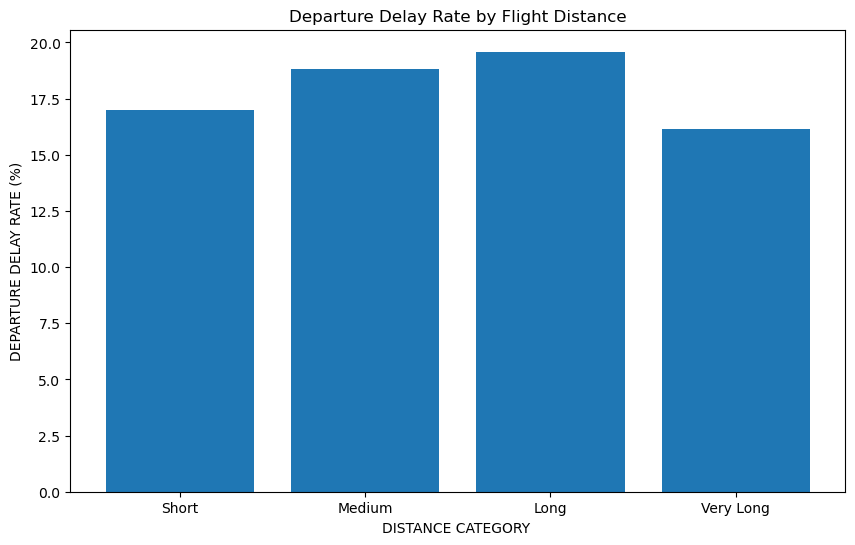

In [49]:
plt.figure(figsize=(10,6))
plt.bar(delay_rate3.index, delay_rate3.values)

plt.xlabel("DISTANCE CATEGORY ")
plt.ylabel("DEPARTURE DELAY RATE (%)")
plt.title("Departure Delay Rate by Flight Distance")
plt.show()

In [50]:
model_df.columns.tolist()

['DAY_OF_WEEK',
 'FL_DATE',
 'OP_UNIQUE_CARRIER',
 'OP_CARRIER_FL_NUM',
 'ORIGIN',
 'DEST',
 'CRS_DEP_TIME',
 'DEP_TIME',
 'DEP_DELAY',
 'DEP_DEL15',
 'CRS_ARR_TIME',
 'CANCELLED',
 'CANCELLATION_CODE',
 'DIVERTED',
 'DISTANCE',
 'DEPART_HOUR',
 'DIST_CATEG']

### DAY OF WEEK FEATURE ANALYSIS

In [51]:
# Check the data type
model_df["DAY_OF_WEEK"].dtype

dtype('int64')

In [52]:
# Examine minimum, maximum, mean, and median 
model_df["DAY_OF_WEEK"].describe()

count    523435.000000
mean          4.021666
std           1.926100
min           1.000000
25%           2.000000
50%           4.000000
75%           6.000000
max           7.000000
Name: DAY_OF_WEEK, dtype: float64

In [53]:
# Check the missing data
model_df["DAY_OF_WEEK"].isna().sum()

np.int64(0)

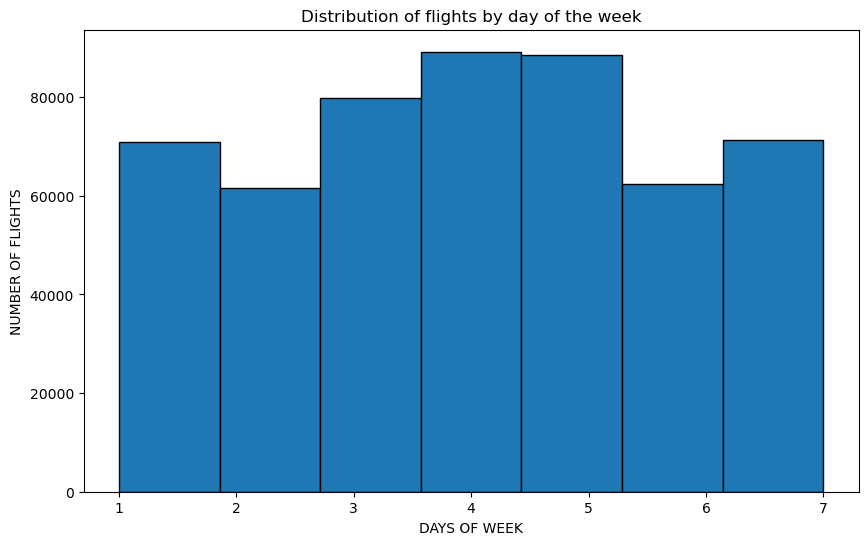

In [54]:
# Check the distribution of flights by day of the week.
plt.figure(figsize=(10,6))
plt.hist(model_df["DAY_OF_WEEK"],bins=7,edgecolor="black")

plt.xlabel("DAYS OF WEEK")
plt.ylabel("NUMBER OF FLIGHTS")
plt.title("Distribution of flights by day of the week")
plt.show()

In [55]:
# Calculate the departure delay rate for each day.
total_flights4 = model_df.groupby("DAY_OF_WEEK").size()
total_flights4

DAY_OF_WEEK
1    70812
2    61560
3    79861
4    89192
5    88487
6    62298
7    71225
dtype: int64

In [56]:
# Delay rate
delay_rate4 = model_df.groupby("DAY_OF_WEEK")["DEP_DEL15"].mean() *100
delay_rate4

DAY_OF_WEEK
1    21.804214
2    14.918778
3    12.917444
4    16.779532
5    18.870569
6    21.305660
7    21.839242
Name: DEP_DEL15, dtype: float64

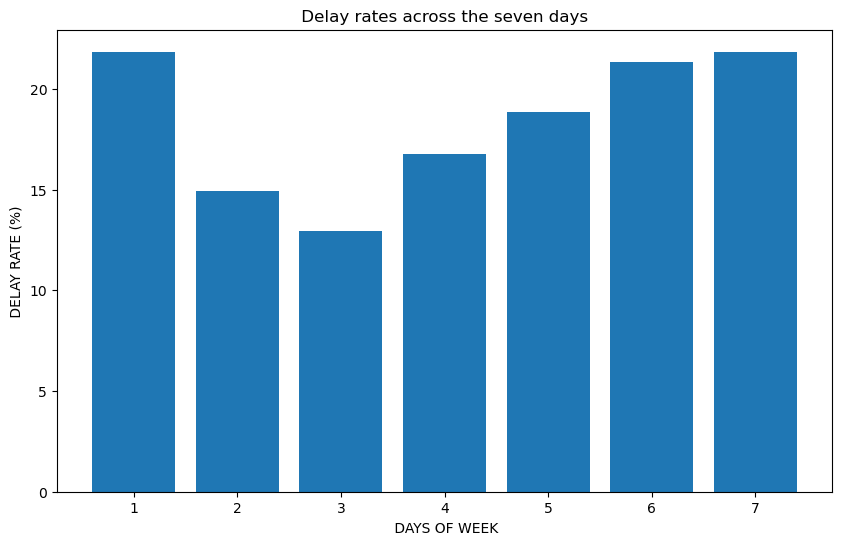

In [57]:
# Visualize delay rates across the seven days.
plt.figure(figsize=(10,6))
plt.bar(delay_rate4.index,delay_rate4.values)

plt.xlabel(" DAYS OF WEEK")
plt.ylabel(" DELAY RATE (%) ")
plt.title (" Delay rates across the seven days ")
plt.show()

#### CONCLUSION
Departure delay rates vary across the week. Sunday (21.84%) and Monday (21.80%) have the highest rates, while Wednesday has the lowest (12.92%). 
Thursday and Friday have the most flights, but not the highest delay rates. 
The difference in delay rates between Wednesday and Sunday may be influenced by other factors, such as scheduled departure times or airport distributions. Further analysis would be needed to explain this pattern.
`DAY_OF_WEEK` may be a useful predictive feature, although the pattern should be validated using data from other periods.


### OP_UNIQUE_CARRIER FEATURE ANALYSIS

In [58]:
# Check data type
model_df["OP_UNIQUE_CARRIER"].dtype

dtype('O')

In [59]:
# Check missing data
model_df["OP_UNIQUE_CARRIER"].isna().sum()

np.int64(0)

In [60]:
# Examine number of unique airlines.
model_df["OP_UNIQUE_CARRIER"].nunique()

14

In [61]:
# Calculate the number of flights operated by each airline.
total_flights5 = model_df.groupby("OP_UNIQUE_CARRIER").size()
total_flights5

OP_UNIQUE_CARRIER
AA     72286
AS     17920
B6     17595
DL     74169
F9     15134
G4      9226
HA      6562
MQ     20860
NK     16972
OH     19195
OO     63693
UA     60818
WN    102291
YX     26714
dtype: int64

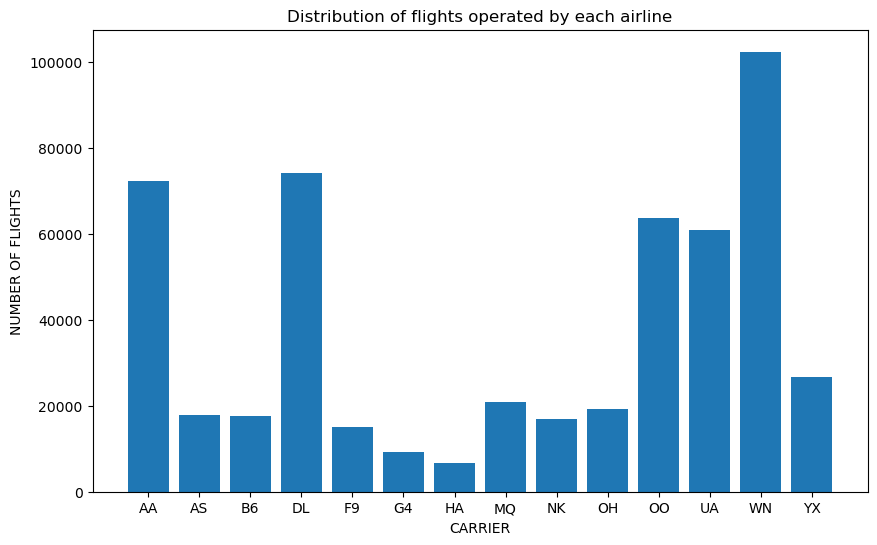

In [62]:
plt.figure(figsize = (10,6))
plt.bar(total_flights5.index, total_flights5.values)

plt.xlabel("CARRIER")
plt.ylabel("NUMBER OF FLIGHTS")
plt.title("Distribution of flights operated by each airline")
plt.show()

In [63]:
# Calculate departure delay rates by airline.
delay_rate5= model_df.groupby("OP_UNIQUE_CARRIER")["DEP_DEL15"].mean()*100
delay_rate5 

OP_UNIQUE_CARRIER
AA    18.768503
AS    16.702009
B6    22.398409
DL    19.582305
F9    23.199419
G4    23.574680
HA    11.368485
MQ    15.743049
NK    18.171105
OH    23.125814
OO    18.699072
UA    16.623368
WN    17.474656
YX    12.252003
Name: DEP_DEL15, dtype: float64

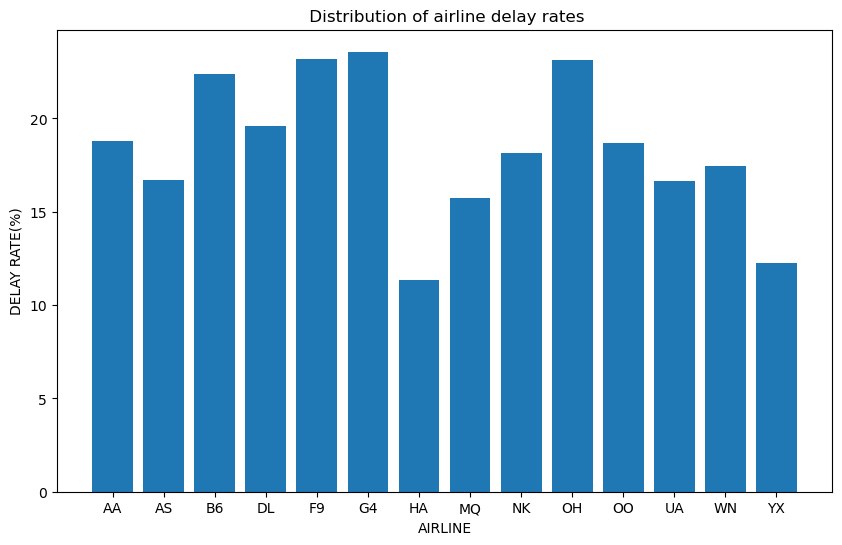

In [64]:
# Visualize and compare airline delay rates.
plt.figure(figsize=(10,6))
plt.bar(delay_rate5.index,delay_rate5.values)

plt.xlabel("AIRLINE")
plt.ylabel("DELAY RATE(%)")
plt.title(" Distribution of airline delay rates")
plt.show()

#### CONCLUSION
Departure delay rates vary across airlines. WN operates the most flights but does not have the highest delay rate. G4 and F9 have higher delay rates despite operating fewer flights.
These differences may also be influenced by departure times, airports, and other operational factors. `OP_UNIQUE_CARRIER` remains a candidate predictive feature.

In [65]:
evening_flights = model_df["DEPART_HOUR"] >= 18
evening_flights.value_counts() 

DEPART_HOUR
False    414245
True     109190
Name: count, dtype: int64

In [72]:
model_df["IS_EVENING"] = evening_flights 

In [67]:
delay_rate6 = model_df.groupby("OP_UNIQUE_CARRIER")["IS_EVENING"].mean()*100
delay_rate6

OP_UNIQUE_CARRIER
AA    22.388844
AS    20.948661
B6    24.302359
DL    21.379552
F9    25.703713
G4    19.488402
HA    11.185614
MQ    21.102589
NK    27.238982
OH    22.234957
OO    19.719592
UA    20.753724
WN    18.895113
YX    18.319982
Name: IS_EVENING, dtype: float64

#### CONCLUSION
Airlines have different proportions of evening flights. However, a higher percentage of evening departures does not consistently correspond to a higher delay rate. Departure time may contribute to airline-level differences, but other factors are likely involved.

In [76]:
delay_rate7 = model_df.groupby(["OP_UNIQUE_CARRIER","IS_EVENING"])["DEP_DEL15"].mean()*100
delay_rate7 

OP_UNIQUE_CARRIER  IS_EVENING
AA                 False         17.120602
                   True          24.480969
AS                 False         15.791331
                   True          20.138519
B6                 False         19.791276
                   True          30.519177
DL                 False         18.401015
                   True          23.926342
F9                 False         20.980078
                   True          29.614396
G4                 False         20.718901
                   True          35.372636
HA                 False         11.153054
                   True          13.079019
MQ                 False         15.269170
                   True          17.514766
NK                 False         14.835209
                   True          27.081981
OH                 False         21.317076
                   True          29.451734
OO                 False         18.917333
                   True          17.810510
UA                 False

In [77]:
delay_rate7.unstack()

IS_EVENING,False,True
OP_UNIQUE_CARRIER,,
AA,17.120602,24.480969
AS,15.791331,20.138519
B6,19.791276,30.519177
DL,18.401015,23.926342
F9,20.980078,29.614396
G4,20.718901,35.372636
HA,11.153054,13.079019
MQ,15.269170,17.514766
NK,14.835209,27.081981


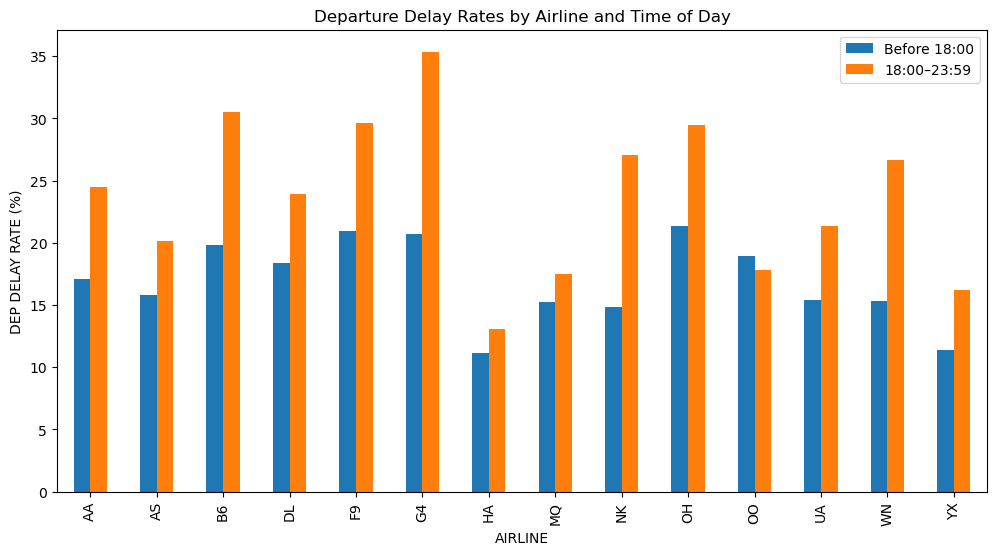

In [88]:
comparison = delay_rate7.unstack()
comparison.columns = ["Before 18:00", "18:00–23:59"]
comparison.plot(kind="bar", figsize=(12, 6))

plt.xlabel("AIRLINE")
plt.ylabel("DEP DELAY RATE (%)")
plt.title("Departure Delay Rates by Airline and Time of Day")
plt.show()

#### CONCLUSION
Evening flights have higher departure delay rates for 13 out of 14 airlines. The largest differences are observed for G4, NK, and WN, while OO is the only exception. This suggests that departure time and airline may provide complementary predictive information.

### DEST FEATURE ANALYSIS

In [80]:
# Check the number of unique destination airports and missing values.
model_df["DEST"].nunique()

329

In [81]:
model_df["DEST"].isna().sum()

np.int64(0)

In [100]:
# Calculate the number of flights for each destination.
total_flights8 = model_df.groupby("DEST").size()
total_flights8 

DEST
ABE     228
ABI     147
ABQ    1762
ABR      61
ABY      63
       ... 
WRG      55
XNA     899
XWA     177
YAK      57
YUM     142
Length: 329, dtype: int64

In [101]:
total_flights8.sort_values(ascending=False).head(5)

DEST
DEN    24372
DFW    23520
ATL    22600
ORD    21220
CLT    16108
dtype: int64

In [86]:
# Calculate departure delay rates by destination airport.
delay_rate8 = model_df.groupby("DEST")["DEP_DEL15"].mean()*100
delay_rate8

DEST
ABE    24.561404
ABI    22.448980
ABQ    16.799092
ABR    18.032787
ABY    25.396825
         ...    
WRG    21.818182
XNA    16.796440
XWA    32.203390
YAK    17.543860
YUM    11.971831
Name: DEP_DEL15, Length: 329, dtype: float64

In [103]:
# Identify destinations with unusually high or low delay rates.
data8 = {
    "total_flights" : total_flights8,
    "delay_rate" : delay_rate8
}
new_df8 = pd.DataFrame(data8)
new_df8

,total_flights,delay_rate
DEST,,
ABE,228,24.561404
ABI,147,22.448980
ABQ,1762,16.799092
ABR,61,18.032787
ABY,63,25.396825
...,...,...
WRG,55,21.818182
XNA,899,16.796440
XWA,177,32.203390


In [110]:
new_df8.sort_values(by="delay_rate",ascending=True).head(5)

,total_flights,delay_rate
DEST,,
EKO,31,0.000000
OTH,18,0.000000
PBG,59,5.084746
LWS,93,5.376344
PIH,61,6.557377


In [109]:
new_df8.sort_values(by="delay_rate",ascending=False).head(5)

,total_flights,delay_rate
DEST,,
CKB,9,55.555556
USA,49,44.897959
COD,61,37.704918
PRC,61,36.065574
JMS,58,34.482759


#### CONCLUSION
Departure delay rates vary across destination airports. However, destinations with the highest and lowest observed rates have fewer than 100 flights, making these estimates less stable.
`DEST` remains a candidate predictive feature, but its contribution needs to be evaluated during model validation.

## TRAIN/VALIDATION SPLIT

### Inspect the Date Range

In [111]:
# Check the data type of FL_DATE.
model_df["FL_DATE"].dtype

dtype('O')

In [119]:
# Check missing data
model_df["FL_DATE"].isna().sum()

np.int64(0)

In [124]:
# Convert FL_DATE to datetime.
model_df["FL_DATE"].copy()
model_df["FL_DATE"] = pd.to_datetime(model_df["FL_DATE"])
model_df["FL_DATE"]

0        2025-01-06
1        2025-01-06
2        2025-01-06
3        2025-01-06
4        2025-01-06
            ...    
539742   2025-01-26
539743   2025-01-26
539744   2025-01-26
539745   2025-01-26
539746   2025-01-26
Name: FL_DATE, Length: 523435, dtype: datetime64[ns]

In [120]:
# Identify the earliest and latest flight dates.
model_df["FL_DATE"].min()

Timestamp('2025-01-01 00:00:00')

In [121]:
model_df["FL_DATE"].max()

Timestamp('2025-01-31 00:00:00')

In [122]:
# Count the number of unique dates.
model_df["FL_DATE"].nunique()

31

#### CONCLUSION
The dataset contains flights from January 1 to January 31, 2025, covering 31 unique dates.
Since no February data is available, I will use a chronological split within January for the initial model evaluation. This allows me to train on earlier flights and validate on later ones.
A longer time period would be useful for evaluating how well the model generalizes across different months.